# Chapitre 4 - Méthodes linéaires de classification
## Cours 2 : LDA de rang réduit et variables canoniques de Fisher

Ce notebook traite la section 4.3.3 du livre. La LDA ne fournit pas seulement une règle
de classification : elle fournit aussi des **projections de faible dimension** des
données, les plus informatives pour distinguer les classes. Nous reproduisons sur les
données de voyelles les figures 4.4, 4.8, 4.10 et 4.11, et illustrons la figure 4.9.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import linalg
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch04_classification as c4
set_style()

In [2]:
Xtr, ytr = datasets.load_vowel("train")
Xte, yte = datasets.load_vowel("test")
K, p = len(np.unique(ytr)), Xtr.shape[1]
print("K =", K, " p =", p, " N_train =", len(ytr), " N_test =", len(yte))

K = 11  p = 10  N_train = 528  N_test = 462


Pour représenter 11 classes, nous utilisons une palette de 11 couleurs : les 8 couleurs
catégorielles du projet, complétées par trois teintes neutres.

In [3]:
VOW = COLORS + ["#52514e", "#8c6d31", "#17becf"]
classes = np.arange(1, 12)

## 1. Pourquoi une réduction de dimension est possible

Rappelons (cours 1) que, après **blanchiment** $x^* = \mathbf{W}^{-1/2}x$ par la covariance
intra-classe $\mathbf{W} = \hat\Sigma$, la LDA classe au **centroïde le plus proche**
(corrigé par $\log\pi_k$).

Les $K$ centroïdes $\mu_1^*, \dots, \mu_K^*$ engendrent un sous-espace affine
$H_{K-1}$ de dimension au plus $K-1$. Décomposons $x^* - \mu_k^*$ en sa composante dans
la direction de $H_{K-1}$ et sa composante orthogonale. Par le théorème de Pythagore,
$$\|x^*-\mu_k^*\|^2 = \|P(x^*) - \mu_k^*\|^2 + \|x^* - P(x^*)\|^2,$$
où $P$ est la projection orthogonale sur $H_{K-1}$. Le second terme **ne dépend pas de
$k$** : il ne joue aucun rôle dans la comparaison.

> **À retenir.** La LDA peut s'effectuer intégralement dans $H_{K-1}$, de dimension
> $K - 1$. Avec $K = 3$ classes, on peut donc voir *toute* l'information utile de la LDA
> dans un plan, quelle que soit la dimension $p$ des données.

Quand $K - 1$ est encore grand (ici $K - 1 = 10 = p$), on cherche un sous-espace
$H_L \subset H_{K-1}$ de dimension $L$ optimal : celui où les centroïdes projetés sont
**le plus dispersés possible**, au sens de la variance.

## 2. Construction des variables canoniques

La procédure du livre comporte trois étapes :

1. calculer la matrice $\mathbf{M}$ ($K\times p$) des centroïdes de classe et la covariance
   intra-classe $\mathbf{W}$ ($p \times p$) ;
2. calculer $\mathbf{M}^* = \mathbf{M}\mathbf{W}^{-1/2}$ (centroïdes blanchis) ;
3. calculer $\mathbf{B}^*$, matrice de covariance (pondérée par les $\pi_k$) des lignes de
   $\mathbf{M}^*$, et sa décomposition spectrale
   $\mathbf{B}^* = \mathbf{V}^*\mathbf{D}_B\mathbf{V}^{*T}$ (valeurs propres décroissantes).

La $\ell$-ième **variable canonique** (ou coordonnée discriminante) est
$Z_\ell = v_\ell^T X$ avec $v_\ell = \mathbf{W}^{-1/2}v_\ell^*$.

Rappel : pour une matrice symétrique définie positive $\mathbf{W} = \mathbf{U}\mathbf{D}\mathbf{U}^T$,
on définit $\mathbf{W}^{-1/2} = \mathbf{U}\mathbf{D}^{-1/2}\mathbf{U}^T$ ; c'est l'unique
matrice symétrique définie positive telle que $(\mathbf{W}^{-1/2})^2 = \mathbf{W}^{-1}$.

Appliquons ces trois étapes « à la main » sur les voyelles.

In [4]:
lda = c4.lda_fit(Xtr, ytr)
M, W, pi = lda["means"], lda["cov"], lda["priors"]
dW, UW = np.linalg.eigh(W)
W_m12 = UW @ np.diag(dW ** -0.5) @ UW.T            # W^{-1/2}
Mstar = M @ W_m12
Mstar_c = Mstar - pi @ Mstar                        # centrage pondéré
Bstar = (Mstar_c * pi[:, None]).T @ Mstar_c
dB, Vstar = np.linalg.eigh(Bstar)
order = np.argsort(dB)[::-1]
dB, Vstar = dB[order], Vstar[:, order]
V_main = W_m12 @ Vstar                              # directions v_l
np.round(dB, 4)

array([3.9676e+00, 2.4853e+00, 3.1460e-01, 1.3520e-01, 7.5300e-02,
       5.8600e-02, 1.8200e-02, 7.5000e-03, 1.0000e-03, 6.0000e-04])

### Le point de vue de Fisher

Fisher aborde la question autrement : trouver la combinaison linéaire $Z = a^TX$ dont la
variance **entre classes** est la plus grande possible relativement à sa variance **à
l'intérieur des classes**. Si $\mathbf{B}$ désigne la covariance des centroïdes (non
blanchis), la variance inter-classes de $Z$ vaut $a^T\mathbf{B}a$ et sa variance
intra-classe $a^T\mathbf{W}a$. Fisher maximise le **quotient de Rayleigh** (éq. (4.15)) :
$$\max_a \frac{a^T\mathbf{B}a}{a^T\mathbf{W}a}
\quad\Longleftrightarrow\quad \max_a a^T\mathbf{B}a \ \text{ sous } \ a^T\mathbf{W}a = 1.$$

Ce problème aux valeurs propres **généralisé** se ramène à un problème standard en posant
$b = \mathbf{W}^{1/2}a$ (exercice 4.1) : on maximise $b^T\mathbf{W}^{-1/2}\mathbf{B}\mathbf{W}^{-1/2}b$
sous $\|b\| = 1$, et $\mathbf{W}^{-1/2}\mathbf{B}\mathbf{W}^{-1/2} = \mathbf{B}^*$. La
solution est donc $a_1 = v_1$, et le maximum vaut la plus grande valeur propre de
$\mathbf{B}^*$. Les directions suivantes $a_2, a_3, \dots$ maximisent le même quotient
sous la contrainte d'être $\mathbf{W}$-orthogonales aux précédentes
($a_\ell^T\mathbf{W}a_m = 0$) : ce sont $v_2, v_3, \dots$

Vérifions numériquement : (i) la fonction `reduced_rank_lda_fit` du module (qui résout
directement $\mathbf{B}v = \lambda\mathbf{W}v$ avec `scipy.linalg.eigh`) donne les mêmes
directions au signe près ; (ii) le quotient de Rayleigh de $v_\ell$ vaut $\lambda_\ell$.

In [5]:
rr = c4.reduced_rank_lda_fit(Xtr, ytr)
V = rr["scalings"]
B = ((M - rr["center"]) * pi[:, None]).T @ (M - rr["center"])
cos = np.abs(np.sum(V * V_main, axis=0)) / (np.linalg.norm(V, axis=0) * np.linalg.norm(V_main, axis=0))
rayleigh = np.array([(v @ B @ v) / (v @ W @ v) for v in V.T])
print("|cos(angle)| entre les deux constructions :", np.round(cos, 6))
print("Quotients de Rayleigh :", np.round(rayleigh, 4))
print("V^T W V = I :", np.allclose(V.T @ W @ V, np.eye(p)))

|cos(angle)| entre les deux constructions : [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Quotients de Rayleigh : [3.9676e+00 2.4853e+00 3.1460e-01 1.3520e-01 7.5300e-02 5.8600e-02
 1.8200e-02 7.5000e-03 1.0000e-03 6.0000e-04]
V^T W V = I : True


Les variances inter-classes décroissent vite : les deux premières variables canoniques
portent l'essentiel de la dispersion des centroïdes.

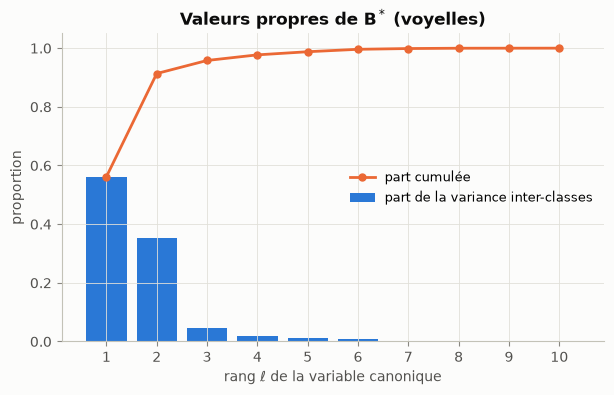

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(np.arange(1, p + 1), rr["eigvals"] / rr["eigvals"].sum(), color=BLUE, label="part de la variance inter-classes")
ax.plot(np.arange(1, p + 1), np.cumsum(rr["eigvals"]) / rr["eigvals"].sum(), "o-", color=ORANGE, label="part cumulée")
ax.set_title("Valeurs propres de $\\mathbf{B}^*$ (voyelles)")
ax.set_xlabel("rang $\\ell$ de la variable canonique")
ax.set_ylabel("proportion")
ax.set_xticks(np.arange(1, p + 1))
ax.legend(loc="center right")
plt.show()

## 3. Visualisation des voyelles (figures 4.4 et 4.8)

On projette les données d'apprentissage sur les deux premières variables canoniques ; les
gros cercles sont les centroïdes projetés.

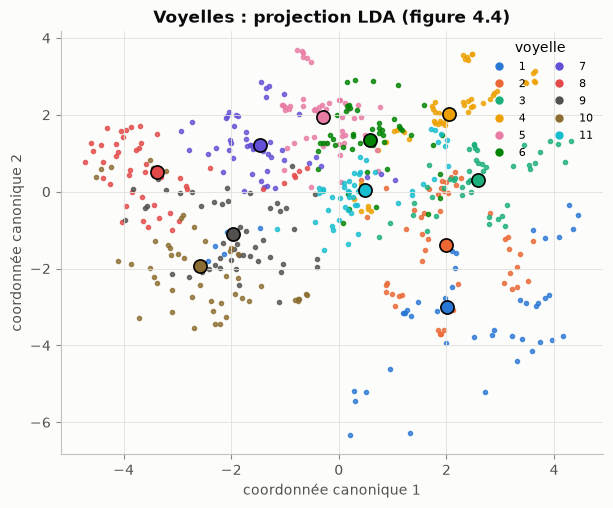

In [7]:
Ztr = c4.reduced_rank_lda_transform(rr, Xtr)
Zc = c4.reduced_rank_lda_transform(rr, M)

def plot_canonical(ax, i, j, title=None):
    for k in range(K):
        ax.scatter(Ztr[ytr == k + 1, i], Ztr[ytr == k + 1, j], s=9, color=VOW[k], alpha=0.8)
        ax.scatter(Zc[k, i], Zc[k, j], s=90, color=VOW[k], edgecolor="k", lw=1.2, zorder=3)
    ax.set_xlabel("coordonnée canonique %d" % (i + 1))
    ax.set_ylabel("coordonnée canonique %d" % (j + 1))
    if title:
        ax.set_title(title)

fig, ax = plt.subplots(figsize=(7, 5.5))
plot_canonical(ax, 0, 1, "Voyelles : projection LDA (figure 4.4)")
handles = [plt.Line2D([], [], marker="o", ls="", color=VOW[k], label=str(k + 1)) for k in range(K)]
ax.legend(handles=handles, title="voyelle", ncol=2, loc="upper right", fontsize=8)
plt.show()